# UCI HAR — Sequence Classification

## Key difference from `experiment_training_medical.ipynb`

| | Window classification (previous) | Sequence classification (this notebook) |
|---|---|---|
| Input | Single window: `(9, 128)` | Sequence of windows: `(seq_len, 9, 128)` |
| Output | One label per window | One label **per position** in the sequence |
| Question answered | *What activity is this 2.56s window?* | *What activity is happening at each moment, and when does it change?* |
| Data order | Windows treated independently (shuffled) | Windows kept in **temporal order** per subject |
| Transition detection | Not possible | Evaluated explicitly |

## Architecture
A two-stage model:
1. **Window encoder** — a small FCN that compresses each `(9, 128)` window into a `d_model`-dimensional embedding
2. **Sequence classifier** — a Transformer encoder that attends across the sequence of embeddings and predicts one activity label per position

This is analogous to a sequence-to-sequence transformer: the input is a sequence of sensor windows and the output is a sequence of activity labels.

In [1]:
import json
import gc
import time
import uuid
from datetime import datetime
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns

from sklearn.metrics import f1_score, accuracy_score, confusion_matrix

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

print(f"PyTorch: {torch.__version__}")
print(f"CUDA available: {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"GPU: {torch.cuda.get_device_name(0)}")

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Device: {DEVICE}")

PyTorch: 2.7.1+cu126
CUDA available: True
GPU: Tesla T4
Device: cuda


In [2]:
# ── Paths ─────────────────────────────────────────────────────────────────────
# Locate the raw UCI HAR data (see datasets/medical/README.md). Resolution order:
#   1. $UCI_HAR_DIR        explicit override (e.g. data outside the repo / on a VM)
#   2. <repo root>/datasets/medical/UCI HAR Dataset   (canonical, CWD-independent)
#   3. CWD-relative fallbacks (Classification/, datasets/medical/, repo root)
import os

def _find_repo_root():
    for parent in [Path.cwd().resolve(), *Path.cwd().resolve().parents]:
        if (parent / "setup.py").is_file() and (parent / "geoxts").is_dir():
            return parent
    return None

_REPO_ROOT = _find_repo_root()
_HAR_CANDIDATES = []
if os.environ.get("UCI_HAR_DIR"):
    _HAR_CANDIDATES.append(Path(os.environ["UCI_HAR_DIR"]))
if _REPO_ROOT is not None:
    _HAR_CANDIDATES.append(_REPO_ROOT / "datasets" / "medical" / "UCI HAR Dataset")
_HAR_CANDIDATES += [
    Path("../UCI HAR Dataset"),                # run from datasets/medical/Classification/
    Path("UCI HAR Dataset"),                   # run from datasets/medical/ (or VM home dir)
    Path("datasets/medical/UCI HAR Dataset"),  # run from repo root
]
HAR_ROOT = next((p for p in _HAR_CANDIDATES if p.exists()), _HAR_CANDIDATES[0])
if not HAR_ROOT.exists():
    raise FileNotFoundError(f"UCI HAR Dataset not found at:\n  {HAR_ROOT.resolve()}\nUpdate HAR_ROOT.")

SAVE_DIR = Path("har_seq")
SAVE_DIR.mkdir(exist_ok=True)

# ── Activity labels ───────────────────────────────────────────────────────────
ACTIVITY_LABELS = [
    "WALKING", "WALKING_UPSTAIRS", "WALKING_DOWNSTAIRS",
    "SITTING", "STANDING", "LAYING"
]
N_CLASSES = len(ACTIVITY_LABELS)

# ── Channel names (same order as raw signal files) ────────────────────────────
CHANNELS = [
    "body_acc_x", "body_acc_y", "body_acc_z",
    "body_gyro_x", "body_gyro_y", "body_gyro_z",
    "total_acc_x", "total_acc_y", "total_acc_z",
]
N_CHANNELS = len(CHANNELS)
WINDOW_LEN = 128

# ── Subject split (same as experiment_training_medical) ───────────────────────
VAL_SUBJECTS = {22, 25, 27, 29}

# ── Window size sweep ─────────────────────────────────────────────────────────
# Each entry: (SEQ_LEN in windows, STRIDE in windows)
# SEQ_LEN × 2.56s = total context window. STRIDE = step between sequences.
SEQ_LEN_VARIANTS = [
    (5,  3),   #  12.8s context, 7.7s step
    (10, 5),   #  25.6s context, 12.8s step
    (20, 10),  #  51.2s context  (original)
    (30, 15),  #  76.8s context
]

# Default SEQ_LEN/STRIDE — used by any standalone cell run outside the sweep
SEQ_LEN, STRIDE = SEQ_LEN_VARIANTS[2]   # 20/10 (original)

# ── Transition tolerance ──────────────────────────────────────────────────────
TOLERANCE = 1   # windows  (1 window = 2.56 s)

# ── Helper: filter subjects with sufficient windows ───────────────────────────
def filter_valid_subjects(subjects, seq_len, subject_window_counts):
    """Return subjects that have at least seq_len windows."""
    valid   = [s for s in subjects if subject_window_counts.get(s, 0) >= seq_len]
    skipped = len(subjects) - len(valid)
    if skipped:
        print(f"  SEQ_LEN={seq_len}: skipping {skipped} subjects with fewer than {seq_len} windows")
    return valid

# ── Model hyperparameters ─────────────────────────────────────────────────────
D_MODEL   = 128     # embedding dimension
N_HEADS   = 4       # transformer attention heads
N_LAYERS  = 2       # transformer encoder layers
DROPOUT   = 0.1

# ── Training hyperparameters ──────────────────────────────────────────────────
BATCH_SIZE      = 32
N_EPOCHS        = 30
LR              = 1e-3
PATIENCE        = 6     # early stopping patience
RANDOM_SEED     = 0

torch.manual_seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)
print("Config OK")
print(f"  SEQ_LEN_VARIANTS: {[(sl, st, f'{sl*2.56:.1f}s') for sl, st in SEQ_LEN_VARIANTS]}")
print(f"  Default SEQ_LEN={SEQ_LEN} ({SEQ_LEN*2.56:.1f}s)  STRIDE={STRIDE}")
print(f"  TOLERANCE=±{TOLERANCE} window (±{TOLERANCE*2.56:.1f}s)")

Config OK
  SEQ_LEN_VARIANTS: [(5, 3, '12.8s'), (10, 5, '25.6s'), (20, 10, '51.2s'), (30, 15, '76.8s')]
  Default SEQ_LEN=20 (51.2s)  STRIDE=10
  TOLERANCE=±1 window (±2.6s)


In [3]:
# ── Load raw data preserving temporal order ───────────────────────────────────
# Unlike the npz files (which were shuffled), this reads directly from the raw
# UCI HAR signal files. Rows are in temporal order within each subject.

def load_raw_split(har_root: Path, split: str):
    """Load all windows for a split in temporal order.
    Returns X (N, 9, 128), y (N,), subjects (N,).
    """
    split_dir = har_root / split
    sig_dir   = split_dir / "Inertial Signals"

    X_channels = []
    for ch in CHANNELS:
        fpath = sig_dir / f"{ch}_{split}.txt"
        X_channels.append(np.loadtxt(fpath, dtype=np.float32))  # (N, 128)
    X = np.stack(X_channels, axis=1)  # (N, 9, 128)

    y        = np.loadtxt(split_dir / f"y_{split}.txt",       dtype=np.int64) - 1  # 0-indexed
    subjects = np.loadtxt(split_dir / f"subject_{split}.txt", dtype=np.int64)

    return X, y, subjects


print("Loading train split...")
X_tr_raw, y_tr_raw, subj_tr = load_raw_split(HAR_ROOT, "train")
print("Loading test split...")
X_te_raw, y_te_raw, subj_te = load_raw_split(HAR_ROOT, "test")

# ── Subject-level train / val split ──────────────────────────────────────────
val_mask   = np.isin(subj_tr, list(VAL_SUBJECTS))
train_mask = ~val_mask

X_train, y_train, subj_train = X_tr_raw[train_mask], y_tr_raw[train_mask], subj_tr[train_mask]
X_val,   y_val,   subj_val   = X_tr_raw[val_mask],   y_tr_raw[val_mask],   subj_tr[val_mask]
X_test,  y_test,  subj_test  = X_te_raw, y_te_raw, subj_te

print(f"\nTrain: {X_train.shape}  subjects: {sorted(set(subj_train.tolist()))}")
print(f"Val:   {X_val.shape}    subjects: {sorted(set(subj_val.tolist()))}")
print(f"Test:  {X_test.shape}   subjects: {sorted(set(subj_test.tolist()))}")

Loading train split...
Loading test split...

Train: (5902, 9, 128)  subjects: [1, 3, 5, 6, 7, 8, 11, 14, 15, 16, 17, 19, 21, 23, 26, 28, 30]
Val:   (1450, 9, 128)    subjects: [22, 25, 27, 29]
Test:  (2947, 9, 128)   subjects: [2, 4, 9, 10, 12, 13, 18, 20, 24]


In [4]:
# ── Z-score normalisation ─────────────────────────────────────────────────────
# Fit on training windows only; apply the same stats to val and test.
# Computed per channel across all timesteps and all training windows.

ch_mean = X_train.mean(axis=(0, 2), keepdims=True)  # (1, 9, 1)
ch_std  = X_train.std(axis=(0, 2), keepdims=True).clip(min=1e-8)

X_train = (X_train - ch_mean) / ch_std
X_val   = (X_val   - ch_mean) / ch_std
X_test  = (X_test  - ch_mean) / ch_std

print("Normalisation applied.")
print(f"  Train mean (all channels): {X_train.mean():.4f}  std: {X_train.std():.4f}")
print(f"  Val   mean (all channels): {X_val.mean():.4f}    std: {X_val.std():.4f}")

Normalisation applied.
  Train mean (all channels): 0.0000  std: 1.0000
  Val   mean (all channels): 0.0579    std: 0.9284


In [5]:
# ── Build sequences of consecutive windows ─────────────────────────────────────
# Sequences are built per subject so no sequence spans a subject boundary.
# A sliding window of size seq_len steps by stride across each subject's windows.
# Called inside the sweep loop with explicit seq_len/stride for each variant.

def build_sequences(X, y, subjects, seq_len=SEQ_LEN, stride=STRIDE):
    """Return (X_seqs, y_seqs, seq_subjects) where:
       X_seqs:      (N_seq, seq_len, 9, 128)  float32
       y_seqs:      (N_seq, seq_len)           int64
       seq_subjects:(N_seq,)                   subject ID of sequence start
    """
    seqs_X, seqs_y, seqs_subj = [], [], []
    for subj in np.unique(subjects):
        mask   = subjects == subj
        X_s    = X[mask]
        y_s    = y[mask]
        n      = len(X_s)
        if n < seq_len:
            continue
        for start in range(0, n - seq_len + 1, stride):
            seqs_X.append(X_s[start:start + seq_len])
            seqs_y.append(y_s[start:start + seq_len])
            seqs_subj.append(subj)
    return (
        np.stack(seqs_X).astype(np.float32),
        np.stack(seqs_y).astype(np.int64),
        np.array(seqs_subj, dtype=np.int64),
    )

print("build_sequences() defined.")

build_sequences() defined.


In [6]:
# ── PyTorch Dataset ───────────────────────────────────────────────────────────
# Instantiation happens inside the sweep loop (seq-train) so SEQ_LEN is correct.

class ActivitySequenceDataset(Dataset):
    """Each item is (X_seq, y_seq).
       X_seq: (seq_len, 9, 128)  float32
       y_seq: (seq_len,)         int64
    """
    def __init__(self, X, y):
        self.X = torch.tensor(X, dtype=torch.float32)
        self.y = torch.tensor(y, dtype=torch.long)

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]

print("ActivitySequenceDataset defined.")

ActivitySequenceDataset defined.


In [7]:
# ── Model: Window Encoder + Transformer Sequence Classifier ───────────────────
# Instantiation happens inside the sweep loop (seq-train) with each variant's SEQ_LEN.

class WindowEncoder(nn.Module):
    """Encodes a single sensor window (C × T) into a d_model-dimensional vector.

    Architecture: 3-layer FCN followed by global average pooling and a linear projection.
    """
    def __init__(self, n_channels: int, d_model: int):
        super().__init__()
        self.conv = nn.Sequential(
            nn.Conv1d(n_channels, 128, kernel_size=8, padding='same'),
            nn.BatchNorm1d(128), nn.ReLU(),
            nn.Conv1d(128, 256, kernel_size=5, padding='same'),
            nn.BatchNorm1d(256), nn.ReLU(),
            nn.Conv1d(256, 128, kernel_size=3, padding='same'),
            nn.BatchNorm1d(128), nn.ReLU(),
        )
        self.pool = nn.AdaptiveAvgPool1d(1)
        self.proj = nn.Linear(128, d_model)

    def forward(self, x):
        # x: (B, C, T)
        h = self.pool(self.conv(x)).squeeze(-1)   # (B, 128)
        return self.proj(h)                        # (B, d_model)


class ActivitySequenceClassifier(nn.Module):
    """Sequence-to-sequence activity classifier.

    Input:  (B, seq_len, C, T)   — batch of window sequences
    Output: (B, seq_len, n_classes) — per-position class logits
    """
    def __init__(
        self,
        n_channels: int,
        n_classes:  int,
        seq_len:    int,
        d_model:    int = D_MODEL,
        n_heads:    int = N_HEADS,
        n_layers:   int = N_LAYERS,
        dropout:    float = DROPOUT,
    ):
        super().__init__()
        self.seq_len = seq_len
        self.window_encoder = WindowEncoder(n_channels, d_model)
        self.pos_embedding  = nn.Embedding(seq_len, d_model)

        enc_layer = nn.TransformerEncoderLayer(
            d_model=d_model,
            nhead=n_heads,
            dim_feedforward=d_model * 4,
            dropout=dropout,
            batch_first=True,
        )
        self.transformer = nn.TransformerEncoder(enc_layer, num_layers=n_layers)
        self.classifier  = nn.Linear(d_model, n_classes)

    def forward(self, x):
        # x: (B, seq_len, C, T)
        B, S, C, T = x.shape
        x_flat = x.reshape(B * S, C, T)
        emb    = self.window_encoder(x_flat).reshape(B, S, -1)
        pos    = torch.arange(S, device=x.device).unsqueeze(0)
        emb    = emb + self.pos_embedding(pos)
        ctx    = self.transformer(emb)
        return self.classifier(ctx)

print("WindowEncoder and ActivitySequenceClassifier defined.")

WindowEncoder and ActivitySequenceClassifier defined.


In [8]:
# ── Sweep over SEQ_LEN_VARIANTS ───────────────────────────────────────────────
# For each (SEQ_LEN, STRIDE) variant: build sequences, create model, train,
# evaluate, log to CSV. The last variant's state is left in module-level
# variables (all_preds, all_labels, model, etc.) for the cells below.

SEQ_LOG_PATH = SAVE_DIR / "experiment_log_seq.csv"

# ── Transition helpers (defined here so sweep can call them) ──────────────────
def get_transitions(seq):
    """Return set of indices where seq[i] != seq[i-1]."""
    return set(np.where(np.diff(seq) != 0)[0] + 1)

def transition_metrics(pred_seqs, true_seqs, tolerance=TOLERANCE):
    """Compute transition detection precision, recall, F1 with positional tolerance."""
    tp, fp, fn = 0, 0, 0
    for pred, true in zip(pred_seqs, true_seqs):
        pred_t = get_transitions(pred)
        true_t = get_transitions(true)
        matched_pred, matched_true = set(), set()
        for pt in pred_t:
            for tt in true_t:
                if abs(pt - tt) <= tolerance and tt not in matched_true:
                    matched_pred.add(pt)
                    matched_true.add(tt)
                    break
        tp += len(matched_pred)
        fp += len(pred_t) - len(matched_pred)
        fn += len(true_t) - len(matched_true)
    precision = tp / (tp + fp) if (tp + fp) > 0 else 0.0
    recall    = tp / (tp + fn) if (tp + fn) > 0 else 0.0
    f1        = (2 * precision * recall / (precision + recall)
                 if (precision + recall) > 0 else 0.0)
    return precision, recall, f1, tp, fp, fn

sweep_results = []   # in-memory summary for post-loop plot

for SEQ_LEN, STRIDE in SEQ_LEN_VARIANTS:
    print(f"\n{'='*60}")
    print(f"SEQ_LEN={SEQ_LEN} ({SEQ_LEN*2.56:.1f}s)  STRIDE={STRIDE}")
    print(f"{'='*60}")

    # ── Filter subjects and build sequences ───────────────────────────────────
    def _wcounts(subjects):
        return {int(s): int((subjects == s).sum()) for s in np.unique(subjects)}

    tr_valid = filter_valid_subjects(np.unique(subj_train).tolist(), SEQ_LEN, _wcounts(subj_train))
    vl_valid = filter_valid_subjects(np.unique(subj_val).tolist(),   SEQ_LEN, _wcounts(subj_val))
    te_valid = filter_valid_subjects(np.unique(subj_test).tolist(),  SEQ_LEN, _wcounts(subj_test))

    tr_mask = np.isin(subj_train, tr_valid)
    vl_mask = np.isin(subj_val,   vl_valid)
    te_mask = np.isin(subj_test,  te_valid)

    X_tr_seq, y_tr_seq, subj_tr_seq = build_sequences(
        X_train[tr_mask], y_train[tr_mask], subj_train[tr_mask], SEQ_LEN, STRIDE)
    X_vl_seq, y_vl_seq, subj_vl_seq = build_sequences(
        X_val[vl_mask],   y_val[vl_mask],   subj_val[vl_mask],   SEQ_LEN, STRIDE)
    X_te_seq, y_te_seq, subj_te_seq = build_sequences(
        X_test[te_mask],  y_test[te_mask],  subj_test[te_mask],  SEQ_LEN, STRIDE)

    print(f"  Train: {X_tr_seq.shape}  Val: {X_vl_seq.shape}  Test: {X_te_seq.shape}")

    # ── Datasets & dataloaders ────────────────────────────────────────────────
    train_dl = DataLoader(ActivitySequenceDataset(X_tr_seq, y_tr_seq),
                          batch_size=BATCH_SIZE, shuffle=True,  num_workers=0, pin_memory=True)
    val_dl   = DataLoader(ActivitySequenceDataset(X_vl_seq, y_vl_seq),
                          batch_size=BATCH_SIZE, shuffle=False, num_workers=0, pin_memory=True)
    test_dl  = DataLoader(ActivitySequenceDataset(X_te_seq, y_te_seq),
                          batch_size=BATCH_SIZE, shuffle=False, num_workers=0, pin_memory=True)

    # ── Model ─────────────────────────────────────────────────────────────────
    torch.manual_seed(RANDOM_SEED); np.random.seed(RANDOM_SEED)
    model = ActivitySequenceClassifier(
        n_channels=N_CHANNELS, n_classes=N_CLASSES, seq_len=SEQ_LEN,
        d_model=D_MODEL, n_heads=N_HEADS, n_layers=N_LAYERS, dropout=DROPOUT,
    ).to(DEVICE)
    print(f"  Parameters: {sum(p.numel() for p in model.parameters() if p.requires_grad):,}")

    # ── Train ─────────────────────────────────────────────────────────────────
    criterion  = nn.CrossEntropyLoss()
    optimiser  = torch.optim.Adam(model.parameters(), lr=LR)
    scheduler  = torch.optim.lr_scheduler.CosineAnnealingLR(optimiser, T_max=N_EPOCHS)
    CKPT_PATH  = SAVE_DIR / f"best_seq_classifier_seqlen{SEQ_LEN}.pth"

    best_val_loss, patience_count = float('inf'), 0
    history = []
    t0 = time.time()

    for epoch in range(1, N_EPOCHS + 1):
        model.train()
        tr_loss, tr_correct, tr_total = 0.0, 0, 0
        for X_b, y_b in train_dl:
            X_b, y_b = X_b.to(DEVICE), y_b.to(DEVICE)
            logits   = model(X_b)
            loss     = criterion(logits.reshape(-1, N_CLASSES), y_b.reshape(-1))
            optimiser.zero_grad(); loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            optimiser.step()
            tr_correct += (logits.argmax(-1) == y_b).sum().item()
            tr_total   += y_b.numel()
            tr_loss    += loss.item() * y_b.numel()
        scheduler.step()

        model.eval()
        vl_loss, vl_correct, vl_total = 0.0, 0, 0
        with torch.no_grad():
            for X_b, y_b in val_dl:
                X_b, y_b = X_b.to(DEVICE), y_b.to(DEVICE)
                logits   = model(X_b)
                loss     = criterion(logits.reshape(-1, N_CLASSES), y_b.reshape(-1))
                vl_correct += (logits.argmax(-1) == y_b).sum().item()
                vl_total   += y_b.numel()
                vl_loss    += loss.item() * y_b.numel()

        tr_l, vl_l = tr_loss / tr_total, vl_loss / vl_total
        tr_a, vl_a = tr_correct / tr_total, vl_correct / vl_total
        history.append({'epoch': epoch, 'train_loss': tr_l, 'val_loss': vl_l,
                        'train_acc': tr_a, 'val_acc': vl_a})

        if vl_l < best_val_loss:
            best_val_loss = vl_l; patience_count = 0
            torch.save(model.state_dict(), CKPT_PATH)
        else:
            patience_count += 1
            if patience_count >= PATIENCE:
                print(f"  Early stop at epoch {epoch}."); break

    train_elapsed = time.time() - t0
    print(f"  Training done in {int(train_elapsed)}s  best_val_loss={best_val_loss:.4f}")

    # ── Evaluate ──────────────────────────────────────────────────────────────
    model.load_state_dict(torch.load(CKPT_PATH, map_location=DEVICE))
    model.eval()

    all_preds_v, all_labels_v = [], []
    with torch.no_grad():
        for X_b, y_b in test_dl:
            logits = model(X_b.to(DEVICE))
            all_preds_v.append(logits.argmax(-1).cpu().numpy())
            all_labels_v.append(y_b.numpy())

    all_preds  = np.concatenate(all_preds_v,  axis=0)
    all_labels = np.concatenate(all_labels_v, axis=0)
    flat_preds  = all_preds.flatten()
    flat_labels = all_labels.flatten()

    test_acc    = accuracy_score(flat_labels, flat_preds)
    test_f1_mac = f1_score(flat_labels, flat_preds, average='macro', zero_division=0)
    per_cls_f1  = f1_score(flat_labels, flat_preds, average=None, zero_division=0)

    prec, rec, t_f1, tp, fp, fn = transition_metrics(all_preds, all_labels)

    print(f"  Accuracy={test_acc:.4f}  Macro-F1={test_f1_mac:.4f}")
    print(f"  Transition recall={rec:.4f}  precision={prec:.4f}  F1={t_f1:.4f}")

    # ── Log to CSV ────────────────────────────────────────────────────────────
    log_row = {
        "run_id":               str(uuid.uuid4()),
        "timestamp":            datetime.now().strftime("%Y-%m-%d %H:%M:%S"),
        "seq_len":              SEQ_LEN,
        "stride":               STRIDE,
        "context_seconds":      round(SEQ_LEN * 2.56, 2),
        "d_model":              D_MODEL,
        "n_heads":              N_HEADS,
        "n_layers":             N_LAYERS,
        "dropout":              DROPOUT,
        "batch_size":           BATCH_SIZE,
        "n_epochs":             N_EPOCHS,
        "lr":                   LR,
        "best_val_loss":        round(best_val_loss, 6),
        "test_accuracy":        round(test_acc, 6),
        "f1_macro":             round(test_f1_mac, 6),
        "transition_recall":    round(rec, 6),
        "transition_precision": round(prec, 6),
        "transition_f1":        round(t_f1, 6),
        "tp": tp, "fp": fp, "fn": fn,
        "train_time_s":         int(train_elapsed),
        "checkpoint":           str(CKPT_PATH),
    }
    log_df_row = pd.DataFrame([log_row])
    if SEQ_LOG_PATH.exists():
        log_df_row.to_csv(SEQ_LOG_PATH, mode="a", header=False, index=False)
    else:
        log_df_row.to_csv(SEQ_LOG_PATH, mode="w", header=True, index=False)

    sweep_results.append({
        "seq_len":           SEQ_LEN,
        "stride":            STRIDE,
        "context_seconds":   round(SEQ_LEN * 2.56, 2),
        "transition_recall": round(rec, 6),
        "f1_macro":          round(test_f1_mac, 6),
    })

    # GPU cleanup between variants
    if DEVICE.type == 'cuda':
        torch.cuda.empty_cache()
    gc.collect()

print(f"\nSweep complete. Results logged to {SEQ_LOG_PATH}")
print(pd.DataFrame(sweep_results).to_string(index=False))


SEQ_LEN=5 (12.8s)  STRIDE=3
  Train: (1952, 5, 9, 128)  Val: (479, 5, 9, 128)  Test: (974, 5, 9, 128)
  Parameters: 687,366


/opt/conda/lib/python3.10/site-packages/torch/nn/modules/conv.py:370: UserWarning: Using padding='same' with even kernel lengths and odd dilation may require a zero-padded copy of the input be created (Triggered internally at /pytorch/aten/src/ATen/native/Convolution.cpp:1036.)
  return F.conv1d(


  Early stop at epoch 7.
  Training done in 7s  best_val_loss=0.0520
  Accuracy=0.9158  Macro-F1=0.9134
  Transition recall=0.9195  precision=0.7784  F1=0.8431

SEQ_LEN=10 (25.6s)  STRIDE=5
  Train: (1157, 10, 9, 128)  Val: (284, 10, 9, 128)  Test: (576, 10, 9, 128)
  Parameters: 688,006
  Early stop at epoch 11.
  Training done in 12s  best_val_loss=0.0546
  Accuracy=0.9457  Macro-F1=0.9462
  Transition recall=0.9610  precision=0.8640  F1=0.9099

SEQ_LEN=20 (51.2s)  STRIDE=10
  Train: (566, 20, 9, 128)  Val: (139, 20, 9, 128)  Test: (282, 20, 9, 128)
  Parameters: 689,286
  Early stop at epoch 22.
  Training done in 23s  best_val_loss=0.0328
  Accuracy=0.9658  Macro-F1=0.9646
  Transition recall=0.9623  precision=0.7816  F1=0.8626

SEQ_LEN=30 (76.8s)  STRIDE=15
  Train: (369, 30, 9, 128)  Val: (91, 30, 9, 128)  Test: (184, 30, 9, 128)
  Parameters: 690,566
  Early stop at epoch 11.
  Training done in 11s  best_val_loss=0.0530
  Accuracy=0.9716  Macro-F1=0.9719
  Transition recall=0.97

Sweep results:


' seq_len  stride  context_seconds  transition_recall  transition_f1  f1_macro\n       5       3             12.8           0.919463       0.843077  0.913375\n      10       5             25.6           0.960976       0.909931  0.946173\n      20      10             51.2           0.962264       0.862579  0.964637\n      30      15             76.8           0.976190       0.881720  0.971924'

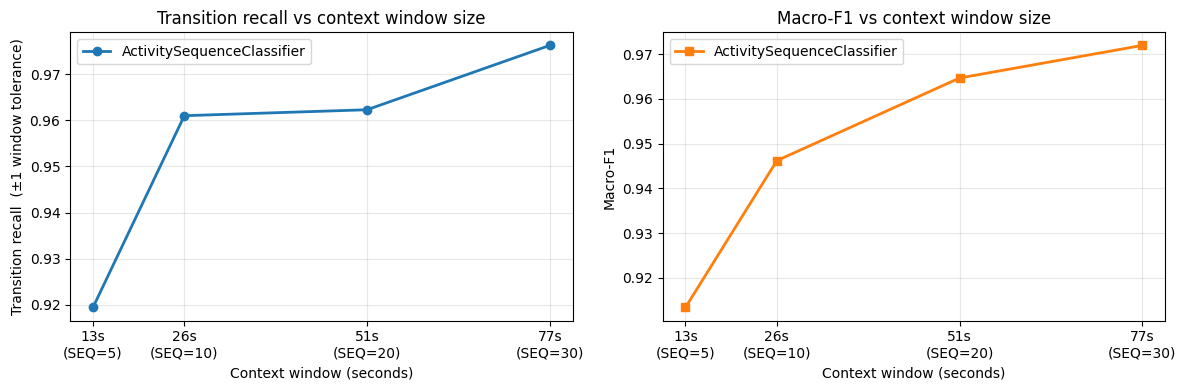


Best SEQ_LEN by transition_recall: 30 (76.8s) → recall=0.9762


In [9]:
# ── Post-sweep summary: transition_recall vs context window size ───────────────
# Reads from the CSV log so this cell works even after a kernel restart.

if SEQ_LOG_PATH.exists():
    sw_df = pd.read_csv(SEQ_LOG_PATH)
else:
    sw_df = pd.DataFrame(sweep_results)   # fall back to in-memory results

print("Sweep results:")
display(sw_df[["seq_len", "stride", "context_seconds",
               "transition_recall", "transition_f1", "f1_macro"]].to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# transition_recall vs context window
axes[0].plot(sw_df["context_seconds"], sw_df["transition_recall"],
             marker='o', linewidth=2, label='ActivitySequenceClassifier')
axes[0].set_xlabel("Context window (seconds)")
axes[0].set_ylabel("Transition recall  (±1 window tolerance)")
axes[0].set_title("Transition recall vs context window size")
axes[0].set_xticks(sw_df["context_seconds"])
axes[0].set_xticklabels([f"{s:.0f}s\n(SEQ={sl})" for s, sl in
                          zip(sw_df["context_seconds"], sw_df["seq_len"])])
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# f1_macro vs context window
axes[1].plot(sw_df["context_seconds"], sw_df["f1_macro"],
             marker='s', linewidth=2, color='tab:orange', label='ActivitySequenceClassifier')
axes[1].set_xlabel("Context window (seconds)")
axes[1].set_ylabel("Macro-F1")
axes[1].set_title("Macro-F1 vs context window size")
axes[1].set_xticks(sw_df["context_seconds"])
axes[1].set_xticklabels([f"{s:.0f}s\n(SEQ={sl})" for s, sl in
                          zip(sw_df["context_seconds"], sw_df["seq_len"])])
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(SAVE_DIR / "seq_len_sweep_summary.png", dpi=150)
plt.show()

best_row = sw_df.loc[sw_df["transition_recall"].idxmax()]
print(f"\nBest SEQ_LEN by transition_recall: {int(best_row['seq_len'])} "
      f"({best_row['context_seconds']:.1f}s) → recall={best_row['transition_recall']:.4f}")

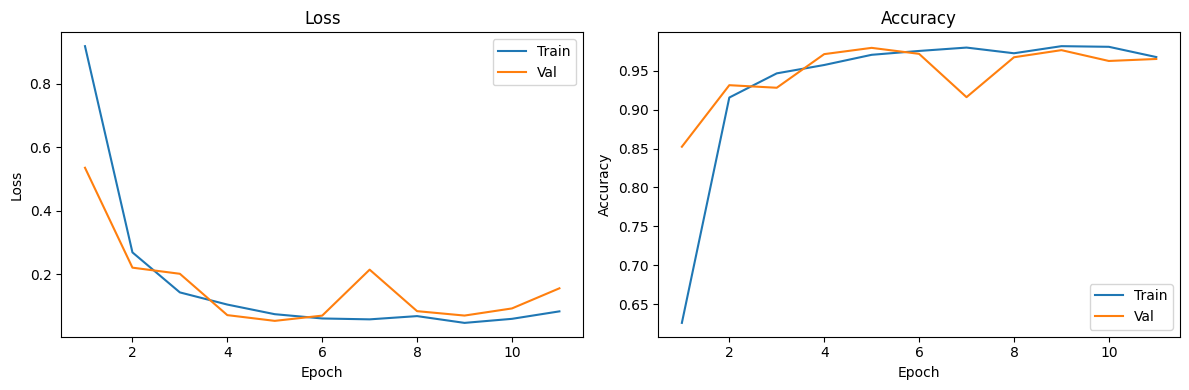

In [10]:
# ── Learning curves ───────────────────────────────────────────────────────────
hist_df = pd.DataFrame(history)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(hist_df['epoch'], hist_df['train_loss'], label='Train')
axes[0].plot(hist_df['epoch'], hist_df['val_loss'],   label='Val')
axes[0].set_xlabel('Epoch'); axes[0].set_ylabel('Loss')
axes[0].set_title('Loss'); axes[0].legend()

axes[1].plot(hist_df['epoch'], hist_df['train_acc'], label='Train')
axes[1].plot(hist_df['epoch'], hist_df['val_acc'],   label='Val')
axes[1].set_xlabel('Epoch'); axes[1].set_ylabel('Accuracy')
axes[1].set_title('Accuracy'); axes[1].legend()

plt.tight_layout()
plt.savefig(SAVE_DIR / 'learning_curves.png', dpi=150)
plt.show()

In [11]:
# ── Test-set evaluation ───────────────────────────────────────────────────────
# Load best checkpoint and evaluate on held-out test subjects.

model.load_state_dict(torch.load(CKPT_PATH, map_location=DEVICE))
model.eval()

all_preds, all_labels = [], []
with torch.no_grad():
    for X_batch, y_batch in test_dl:
        logits = model(X_batch.to(DEVICE))             # (B, S, C)
        preds  = logits.argmax(dim=-1).cpu().numpy()   # (B, S)
        all_preds.append(preds)
        all_labels.append(y_batch.numpy())

all_preds  = np.concatenate(all_preds,  axis=0)   # (N_seq, S)
all_labels = np.concatenate(all_labels, axis=0)   # (N_seq, S)

flat_preds  = all_preds.flatten()
flat_labels = all_labels.flatten()

test_acc     = accuracy_score(flat_labels, flat_preds)
test_f1_mac  = f1_score(flat_labels, flat_preds, average='macro',  zero_division=0)
per_cls_f1   = f1_score(flat_labels, flat_preds, average=None,     zero_division=0)

print(f"Test accuracy:  {test_acc:.4f}")
print(f"Macro-F1:       {test_f1_mac:.4f}")
print()
print("Per-class F1:")
for name, f1 in zip(ACTIVITY_LABELS, per_cls_f1):
    print(f"  {name:<25} {f1:.4f}")

Test accuracy:  0.9716
Macro-F1:       0.9719

Per-class F1:
  WALKING                   0.9935
  WALKING_UPSTAIRS          0.9836
  WALKING_DOWNSTAIRS        0.9809
  SITTING                   0.9371
  STANDING                  0.9565
  LAYING                    0.9799


In [12]:
# ── Transition detection metrics ──────────────────────────────────────────────
# This is the key metric that distinguishes this evaluation from window
# classification. A transition is any position in a sequence where the
# activity label changes. We measure how accurately the model detects them.
#
# A predicted transition counts as correct if it falls within ±TOLERANCE
# windows of a true transition.

TOLERANCE = 1  # windows  (1 window = 2.56 s)

def get_transitions(seq):
    """Return set of indices where seq[i] != seq[i-1]."""
    return set(np.where(np.diff(seq) != 0)[0] + 1)


def transition_metrics(pred_seqs, true_seqs, tolerance=TOLERANCE):
    tp, fp, fn = 0, 0, 0
    for pred, true in zip(pred_seqs, true_seqs):
        pred_t = get_transitions(pred)
        true_t = get_transitions(true)

        matched_pred = set()
        matched_true = set()
        for pt in pred_t:
            for tt in true_t:
                if abs(pt - tt) <= tolerance and tt not in matched_true:
                    matched_pred.add(pt)
                    matched_true.add(tt)
                    break

        tp += len(matched_pred)
        fp += len(pred_t) - len(matched_pred)
        fn += len(true_t) - len(matched_true)

    precision = tp / (tp + fp) if (tp + fp) > 0 else 0.0
    recall    = tp / (tp + fn) if (tp + fn) > 0 else 0.0
    f1        = (2 * precision * recall / (precision + recall)
                 if (precision + recall) > 0 else 0.0)
    return precision, recall, f1, tp, fp, fn


prec, rec, t_f1, tp, fp, fn = transition_metrics(all_preds, all_labels)

print(f"Transition detection  (tolerance = ±{TOLERANCE} window = ±{TOLERANCE*2.56:.1f}s)")
print(f"  Precision: {prec:.4f}")
print(f"  Recall:    {rec:.4f}")
print(f"  F1:        {t_f1:.4f}")
print(f"  TP={tp}  FP={fp}  FN={fn}")

# Total transitions in ground truth
total_true_trans = sum(len(get_transitions(seq)) for seq in all_labels)
total_pred_trans = sum(len(get_transitions(seq)) for seq in all_preds)
print(f"\n  True transitions in test: {total_true_trans}")
print(f"  Predicted transitions:    {total_pred_trans}")

Transition detection  (tolerance = ±1 window = ±2.6s)
  Precision: 0.8039
  Recall:    0.9762
  F1:        0.8817
  TP=205  FP=50  FN=5

  True transitions in test: 210
  Predicted transitions:    255


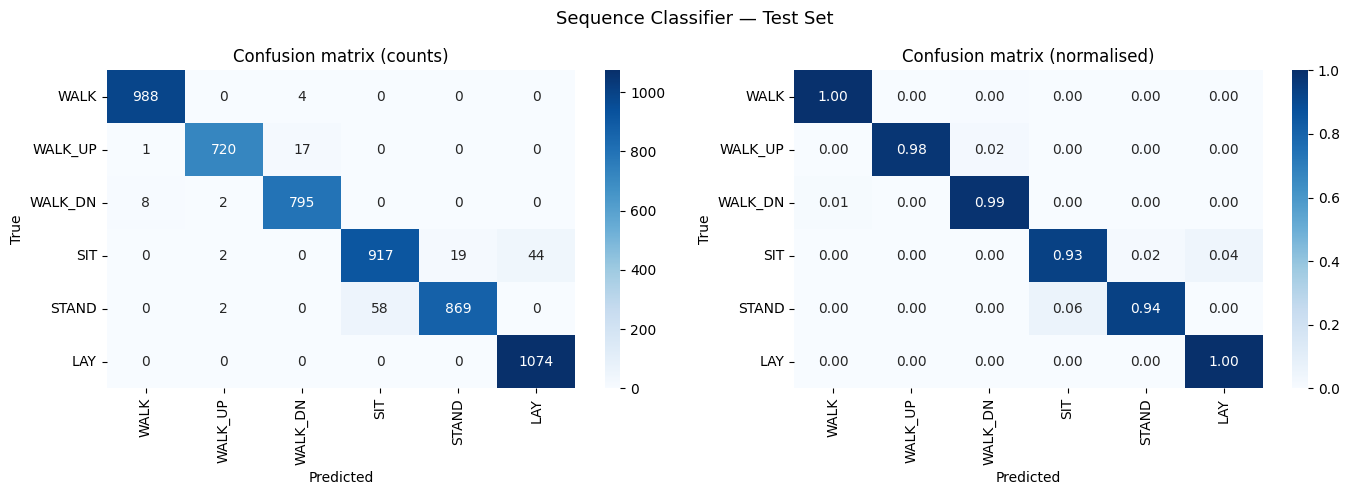

In [13]:
# ── Confusion matrix ──────────────────────────────────────────────────────────
cm      = confusion_matrix(flat_labels, flat_preds, labels=list(range(N_CLASSES)))
cm_norm = cm.astype(float) / cm.sum(axis=1, keepdims=True).clip(min=1)

short_names = ["WALK", "WALK_UP", "WALK_DN", "SIT", "STAND", "LAY"]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.heatmap(cm,      annot=True, fmt='d',    cmap='Blues',
            xticklabels=short_names, yticklabels=short_names, ax=axes[0])
axes[0].set_title('Confusion matrix (counts)')
axes[0].set_ylabel('True'); axes[0].set_xlabel('Predicted')

sns.heatmap(cm_norm, annot=True, fmt='.2f', cmap='Blues',
            xticklabels=short_names, yticklabels=short_names, ax=axes[1])
axes[1].set_title('Confusion matrix (normalised)')
axes[1].set_ylabel('True'); axes[1].set_xlabel('Predicted')

plt.suptitle('Sequence Classifier — Test Set', fontsize=13)
plt.tight_layout()
plt.savefig(SAVE_DIR / 'confusion_matrix.png', dpi=150)
plt.show()

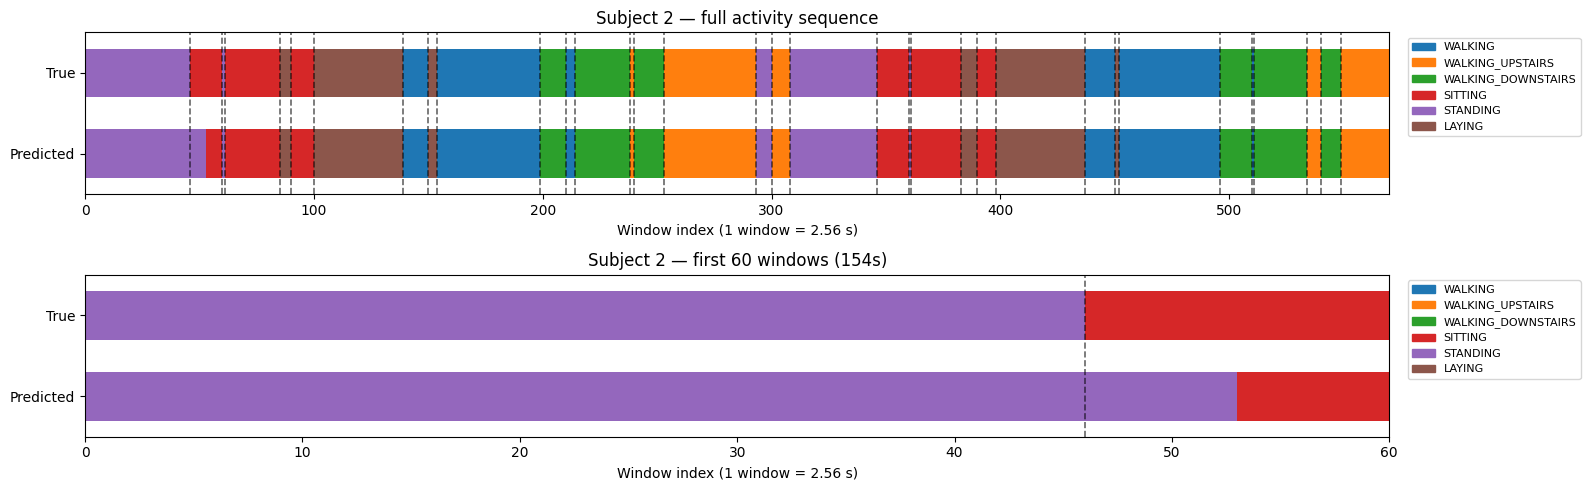

True transitions in this subject's sequence: 33
Predicted transitions:                        33


In [14]:
# ── Activity timeline visualisation ──────────────────────────────────────────
# Show predicted vs true activity label over time for a sample test subject.
# This is the core output that window classification cannot produce.

COLOURS = plt.cm.tab10.colors[:N_CLASSES]

def plot_activity_timeline(true_seq, pred_seq, title="Activity timeline", ax=None):
    if ax is None:
        fig, ax = plt.subplots(figsize=(14, 2.5))
    T = len(true_seq)
    ax.set_xlim(0, T)
    ax.set_ylim(-0.5, 1.5)
    ax.set_yticks([0, 1])
    ax.set_yticklabels(['Predicted', 'True'])
    ax.set_xlabel('Window index (1 window = 2.56 s)')

    for t in range(T):
        ax.barh(0, 1, left=t, height=0.6, color=COLOURS[pred_seq[t]], align='center')
        ax.barh(1, 1, left=t, height=0.6, color=COLOURS[true_seq[t]], align='center')

    # Mark true transitions
    for tt in get_transitions(true_seq):
        ax.axvline(x=tt, color='black', linewidth=1.2, linestyle='--', alpha=0.6)

    patches = [mpatches.Patch(color=COLOURS[i], label=ACTIVITY_LABELS[i])
               for i in range(N_CLASSES)]
    ax.legend(handles=patches, bbox_to_anchor=(1.01, 1), loc='upper left', fontsize=8)
    ax.set_title(title)
    return ax


# Reconstruct one full subject's sequence from the test sequences
# Find sequences belonging to the first test subject (in order)
first_subj = subj_te_seq[0]
subj_mask  = subj_te_seq == first_subj
true_full  = all_labels[subj_mask].flatten()
pred_full  = all_preds[subj_mask].flatten()

fig, axes = plt.subplots(2, 1, figsize=(16, 5))
plot_activity_timeline(true_full, pred_full,
                       title=f"Subject {first_subj} — full activity sequence",
                       ax=axes[0])

# Zoom into first 60 windows (~2.5 minutes)
zoom = 60
plot_activity_timeline(true_full[:zoom], pred_full[:zoom],
                       title=f"Subject {first_subj} — first {zoom} windows ({zoom*2.56:.0f}s)",
                       ax=axes[1])

plt.tight_layout()
plt.savefig(SAVE_DIR / 'activity_timeline.png', dpi=150)
plt.show()

print(f"True transitions in this subject's sequence: {len(get_transitions(true_full))}")
print(f"Predicted transitions:                        {len(get_transitions(pred_full))}")

In [15]:
# ── Results summary ───────────────────────────────────────────────────────────
print("=" * 55)
print("SEQUENCE CLASSIFIER — FINAL RESULTS")
print("=" * 55)
print(f"  SEQ_LEN   : {SEQ_LEN} windows ({SEQ_LEN*2.56:.1f}s)")
print(f"  STRIDE    : {STRIDE} windows")
print(f"  D_MODEL   : {D_MODEL}")
print(f"  N_LAYERS  : {N_LAYERS}")
print()
print(f"  Test accuracy   : {test_acc:.4f}")
print(f"  Test macro-F1   : {test_f1_mac:.4f}")
print()
print("  Per-class F1:")
for name, f1 in zip(ACTIVITY_LABELS, per_cls_f1):
    print(f"    {name:<25} {f1:.4f}")
print()
print(f"  Transition precision : {prec:.4f}")
print(f"  Transition recall    : {rec:.4f}")
print(f"  Transition F1        : {t_f1:.4f}")
print(f"  (tolerance = ±{TOLERANCE} window = ±{TOLERANCE*2.56:.1f}s)")
print("=" * 55)

SEQUENCE CLASSIFIER — FINAL RESULTS
  SEQ_LEN   : 30 windows (76.8s)
  STRIDE    : 15 windows
  D_MODEL   : 128
  N_LAYERS  : 2

  Test accuracy   : 0.9716
  Test macro-F1   : 0.9719

  Per-class F1:
    WALKING                   0.9935
    WALKING_UPSTAIRS          0.9836
    WALKING_DOWNSTAIRS        0.9809
    SITTING                   0.9371
    STANDING                  0.9565
    LAYING                    0.9799

  Transition precision : 0.8039
  Transition recall    : 0.9762
  Transition F1        : 0.8817
  (tolerance = ±1 window = ±2.6s)
